# <center>Computação Numérica — Projeto da Unidade II</center>
## <center>Identificação / Filtragem de um Sistema Dinâmico com RBF e MMQ</center>

**O que este notebook faz, em uma frase:** recebe os sinais medidos (com ruído) de um sistema físico em operação e obtém modelos matemáticos que os representam, avaliando cada modelo pelo **Erro Médio Quadrático (EMQ)** e pela **Correlação de Pearson ($r$)**.

### Os dados (`dados_projeto_02.csv`)
| Coluna | Significado |
|---|---|
| `t` | tempo (s), de 0 a 30 s, amostrado a cada $\Delta t = 0{,}02$ s (1501 amostras) |
| `u` | sinal de **entrada** do sistema: onda quadrada que alterna entre $+1$ e $-1$ |
| `x_ruido` | **saída 01** do sistema, medida com ruído |
| `y_ruido` | **saída 02** do sistema, medida com ruído |

### O modelo pedido no enunciado
$$y[n] = f\big(y[n-2],\; y[n-1],\; u[n],\; u[n-1]\big)$$
Ou seja: o valor da saída **agora** ($n$) depende dos **dois valores anteriores** da própria saída e dos valores **atual e anterior** da entrada. (O mesmo vale para a saída $x$.)

### Roteiro (cada item da avaliação → seção do notebook)
| Item do enunciado | Pontos | Onde está |
|---|---|---|
| Ajuste via Funções de Base Radial (RBF) | 2,0 | Seção 3 (Etapa 01) |
| Erro Médio Quadrático (EMQ) | 1,0 | Seção 3 (Etapa 02) |
| Regressão linear entre dados reais e ajustados | 1,0 | Seção 3 (Etapa 03) |
| Coeficiente de Correlação de Pearson | 2,0 | Seção 3 (Etapa 03) |
| Repetir o processo com o Método dos Mínimos Quadrados (MMQ) | 2,0 | Seção 4 (Etapa 04) |
| Conclusões | 2,0 | Seção 6 |

Bibliotecas usadas: apenas **NumPy** (vetores e álgebra linear) e **Matplotlib** (gráficos). Todas as fórmulas (RBF, equação normal, EMQ, Pearson, regressão) foram implementadas "na mão".

In [1]:
import csv                        # leitor de CSV da biblioteca padrão do Python (só para separar as colunas)
import numpy as np                # vetores, matrizes e álgebra linear
import matplotlib.pyplot as plt   # gráficos

# Aparência dos gráficos: grade discreta e sem bordas superior/direita
plt.rcParams.update({"axes.grid": True, "grid.linestyle": ":", "grid.alpha": 0.5,
                     "axes.spines.top": False, "axes.spines.right": False})

# Cores usadas em todo o notebook (sempre o mesmo papel para a mesma cor)
COR_MEDIDO = "#2a78d6"   # azul    -> dados medidos (com ruído)
COR_MODELO = "#eb6834"   # laranja -> saída do modelo
COR_ENTRADA = "#52514e"  # cinza   -> sinal de entrada u(t)

---
## 1. Leitura dos dados

O arquivo usa **vírgula como separador decimal** (padrão brasileiro: `"0,02"`), e os números com vírgula vêm entre aspas para não serem confundidos com o separador de colunas. Por isso:
1. o módulo `csv` separa as 4 colunas respeitando as aspas;
2. trocamos `,` por `.` em cada valor e convertemos para `float`.

In [2]:
linhas = []
with open("dados_projeto_02.csv", "r", encoding="utf-8") as arquivo:
    leitor = csv.reader(arquivo)
    cabecalho = next(leitor)                      # primeira linha: nomes das colunas
    for linha in leitor:
        if linha:                                 # ignora linhas vazias
            linhas.append([float(valor.replace(",", ".")) for valor in linha])

dados = np.array(linhas)                          # matriz (1501 linhas x 4 colunas)
t = dados[:, 0]   # tempo (s)
u = dados[:, 1]   # entrada
x = dados[:, 2]   # saída 01 medida (com ruído)
y = dados[:, 3]   # saída 02 medida (com ruído)
N = len(t)

print("Colunas:", cabecalho)
print(f"Número de amostras N = {N}  |  t de {t[0]} a {t[-1]} s  |  Δt = {t[1] - t[0]:.2f} s")
print("Primeiras 3 linhas:\n", dados[:3])

Colunas: ['t', 'u', 'x_ruido', 'y_ruido']
Número de amostras N = 1501  |  t de 0.0 a 30.0 s  |  Δt = 0.02 s
Primeiras 3 linhas:
 [[ 0.        0.        0.030472 -0.043722]
 [ 0.02      1.       -0.103998  0.09276 ]
 [ 0.04      1.        0.075178  0.036407]]


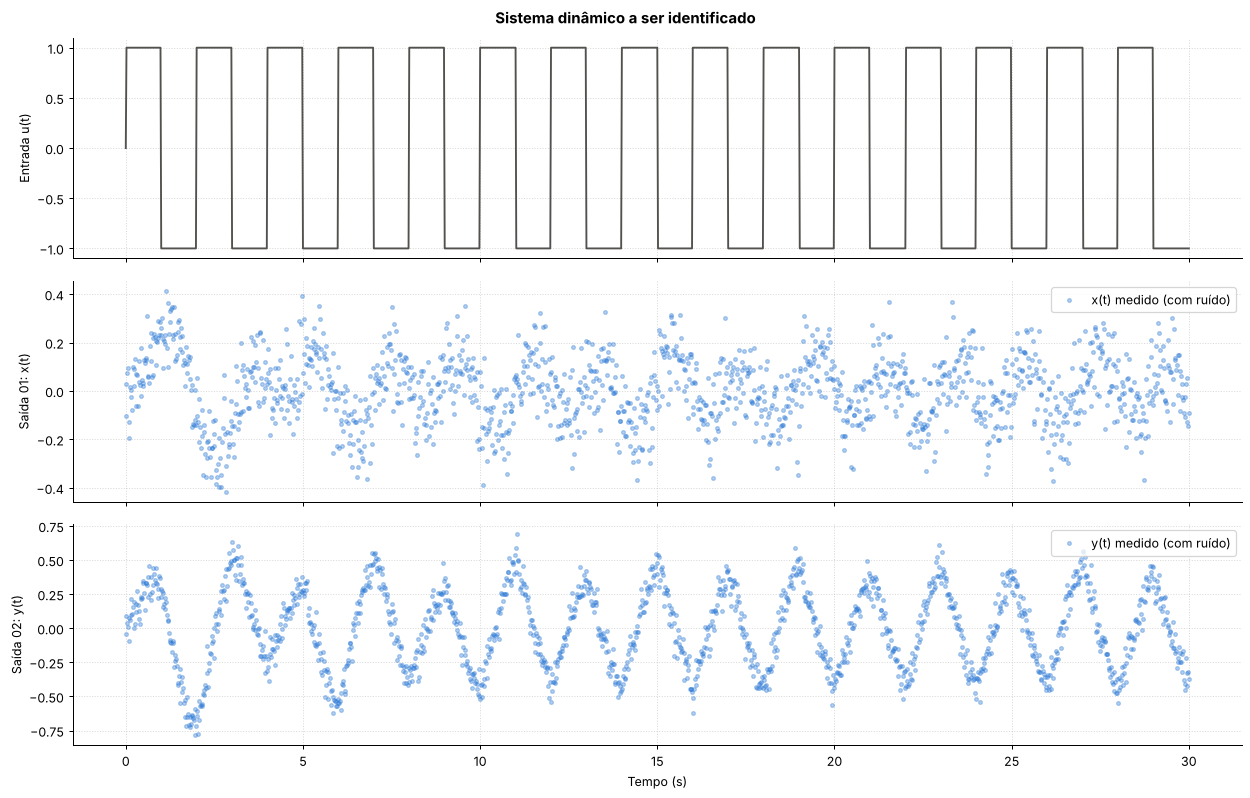

In [3]:
fig, ax = plt.subplots(3, 1, figsize=(14, 9), sharex=True)
fig.suptitle("Sistema dinâmico a ser identificado", fontweight="bold")

ax[0].plot(t, u, color=COR_ENTRADA, lw=1.5)
ax[0].set_ylabel("Entrada u(t)")

ax[1].plot(t, x, "o", ms=3, alpha=0.35, color=COR_MEDIDO, label="x(t) medido (com ruído)")
ax[1].set_ylabel("Saída 01: x(t)"); ax[1].legend(loc="upper right")

ax[2].plot(t, y, "o", ms=3, alpha=0.35, color=COR_MEDIDO, label="y(t) medido (com ruído)")
ax[2].set_ylabel("Saída 02: y(t)"); ax[2].set_xlabel("Tempo (s)"); ax[2].legend(loc="upper right")

plt.tight_layout()
plt.show()

**O que observar:**
* A entrada $u$ troca de sinal a cada 1 s (período de 2 s).
* As duas saídas oscilam acompanhando a entrada, mas estão **muito ruidosas** — principalmente $x(t)$, cujo ruído é quase do tamanho do próprio sinal.
* O objetivo é encontrar uma curva/modelo que represente o **comportamento verdadeiro** escondido atrás do ruído.

---
## 2. Ferramentas de avaliação (usadas pelos dois métodos)

### 2.1 Erro Médio Quadrático (EMQ)
$$\text{EMQ} = \frac{1}{N}\sum_{i=1}^{N}\big(y_i - \hat y_i\big)^2$$
* $y_i$: valor medido; $\hat y_i$: valor do modelo.
* Elevar ao quadrado deixa todos os erros positivos e pune mais os erros grandes.
* Quanto **menor**, melhor. Unidade: (unidade do sinal)². Por isso $\sqrt{\text{EMQ}}$ (o RMSE) é o "erro típico" na mesma unidade do sinal.
* **Limite importante:** como os dados têm ruído, nenhum modelo honesto chega a EMQ = 0. O melhor EMQ possível é aproximadamente a **variância do ruído**.

### 2.2 Coeficiente de Correlação de Pearson ($r$)
$$r = \frac{\sum_i (y_i - \bar y)(\hat y_i - \bar{\hat y})}{\sqrt{\sum_i (y_i-\bar y)^2}\;\sqrt{\sum_i(\hat y_i - \bar{\hat y})^2}}$$
* Mede o quanto dois sinais "andam juntos" de forma **linear**. Vai de $-1$ a $+1$.
* $r = 1$: relação linear perfeita; $r \approx 0$: nenhuma relação linear.
* $r^2$ é a fração da variação dos dados explicada pelo modelo.

### 2.3 Regressão linear entre dados reais e ajustados
Ajustamos uma reta $y_{\text{real}} \approx \alpha + \beta\,\hat y$ pelo MMQ (equação normal $2\times 2$, igual à da aula):
$$\begin{bmatrix} N & \sum \hat y_i \\ \sum \hat y_i & \sum \hat y_i^2 \end{bmatrix}\begin{bmatrix}\alpha\\ \beta\end{bmatrix} = \begin{bmatrix}\sum y_i \\ \sum \hat y_i\, y_i\end{bmatrix}$$
Se o modelo for bom, os pontos ficam perto da reta, com **inclinação $\beta \approx 1$** e **intercepto $\alpha \approx 0$** (o modelo não "sobe" nem "desce" os dados sistematicamente).

In [4]:
def emq(real, ajustado):
    # Erro Médio Quadrático: média dos erros ao quadrado
    erro = real - ajustado
    return np.sum(erro ** 2) / len(erro)

def pearson(a, b):
    # Coeficiente de correlação de Pearson, implementado pela fórmula
    da = a - np.mean(a)              # desvios em relação à média
    db = b - np.mean(b)
    return np.sum(da * db) / np.sqrt(np.sum(da ** 2) * np.sum(db ** 2))

def regressao_linear(xr, yr):
    # Reta yr = alfa + beta * xr pelo MMQ (sistema 2x2 da equação normal)
    A = np.array([[len(xr),     np.sum(xr)],
                  [np.sum(xr),  np.sum(xr * xr)]])
    B = np.array([np.sum(yr), np.sum(xr * yr)])
    alfa, beta = np.linalg.solve(A, B)
    return alfa, beta

# Teste rápido: comparando o nosso Pearson com o da NumPy (devem ser iguais)
a_teste, b_teste = np.array([1.0, 2, 3, 4]), np.array([1.1, 1.9, 3.2, 3.9])
print(f"Pearson (nosso) = {pearson(a_teste, b_teste):.6f} | Pearson (np.corrcoef) = {np.corrcoef(a_teste, b_teste)[0, 1]:.6f}")

Pearson (nosso) = 0.993371 | Pearson (np.corrcoef) = 0.993371


---
## 3. Parte A — Ajuste via Funções de Base Radial (RBF)

### 3.1 A ideia
Uma **função de base radial gaussiana** é um "sino" centrado em $c_j$ com largura $\sigma$:
$$\phi_j(t) = \exp\!\left(-\frac{(t - c_j)^2}{2\sigma^2}\right)$$
Ela vale 1 no centro e cai para perto de 0 longe dele. Somando vários sinos, cada um multiplicado por um peso, conseguimos desenhar **qualquer curva suave**:
$$\hat s(t) = w_0 + \sum_{j=1}^{M} w_j\,\phi_j(t)$$

Aqui usamos a RBF para **filtrar** cada saída medida ($x$ e $y$): espalhamos $M$ gaussianas ao longo do tempo e ajustamos os pesos para a curva passar "pelo meio" dos pontos ruidosos. O ruído é rápido e aleatório; a curva suave não consegue segui-lo, então ela captura só a dinâmica verdadeira do sistema. (O enunciado diz que o projeto é a *"identificação da dinâmica **ou** filtragem"*; a RBF faz a filtragem e o MMQ, na Parte B, faz a identificação da dinâmica.)

### 3.2 Parâmetros livres do modelo RBF
| Parâmetro | Como foi escolhido |
|---|---|
| $M$ (número de gaussianas) | por **validação** (Seção 3.3) |
| $c_j$ (centros) | igualmente espaçados de 0 a 30 s |
| $\sigma$ (largura) | igual ao espaçamento entre centros (regra prática da aula: sinos vizinhos se sobrepõem sem ficarem iguais) |
| $w_0, w_1, \dots, w_M$ (pesos) | calculados pela **equação normal** (MMQ) |

### 3.3 Como achar os pesos: matriz de projeto e equação normal
Para os $N$ instantes de tempo, montamos a **matriz de projeto** $\Phi$ ($N \times (M+1)$), com a 1ª coluna de 1s (para $w_0$):
$$\Phi = \begin{bmatrix} 1 & \phi_1(t_1) & \cdots & \phi_M(t_1)\\ \vdots & \vdots & \ddots & \vdots \\ 1 & \phi_1(t_N) & \cdots & \phi_M(t_N)\end{bmatrix}, \qquad \hat{\mathbf s} = \Phi\,\mathbf w$$
O modelo é **não linear em $t$**, mas **linear nos pesos $\mathbf w$**. Por isso o problema "minimizar o EMQ" tem solução direta: derivando o EMQ em relação a $\mathbf w$ e igualando a zero, chega-se à **equação normal**
$$\boxed{\Phi^T\Phi\,\mathbf w = \Phi^T\mathbf s}$$
que é um sistema linear. Resolvemos com `np.linalg.solve` (mais preciso que calcular a inversa explicitamente).

In [5]:
def matriz_phi(tempos, centros, sigma):
    # Matriz de projeto: coluna de 1s + uma coluna gaussiana para cada centro
    Phi = np.zeros((len(tempos), len(centros) + 1))
    Phi[:, 0] = 1.0                                         # coluna do bias w0
    for j in range(len(centros)):
        Phi[:, j + 1] = np.exp(-(tempos - centros[j]) ** 2 / (2 * sigma ** 2))
    return Phi

def ajustar_rbf(tempos, sinal, M):
    # Centros igualmente espaçados, sigma = espaçamento, pesos pela equação normal
    centros = np.linspace(0, 30, M)
    sigma = centros[1] - centros[0]
    Phi = matriz_phi(tempos, centros, sigma)
    w = np.linalg.solve(Phi.T @ Phi, Phi.T @ sinal)        # (Φᵀ Φ) w = Φᵀ s
    return w, centros, sigma

### 3.4 Escolhendo o número de gaussianas $M$ (validação)
* **Poucas** gaussianas → a curva é rígida demais e não acompanha o sinal (*subajuste*).
* **Gaussianas demais** → a curva fica tão flexível que passa a copiar o ruído (*sobreajuste*).

Para escolher sem "chute": separamos **1 de cada 5 amostras** como conjunto de **validação** (o modelo não as vê), ajustamos com as outras 4 e medimos o EMQ nas amostras escondidas. Um bom $M$ é o que **erra pouco nos dados que não viu**.

Como a curva de validação fica quase plana perto do mínimo, usamos a **regra da parcimônia** (vista no mini projeto): escolher o **modelo mais simples** (menor $M$) cujo erro de validação esteja no máximo 2% acima do menor erro encontrado. Menos parâmetros = modelo mais estável e mais fácil de interpretar.

x(t): menor EMQ de validação = 0.00998 (M = 40)  ->  M escolhido = 40 (EMQ = 0.00998)
y(t): menor EMQ de validação = 0.00578 (M = 110)  ->  M escolhido = 50 (EMQ = 0.00587)


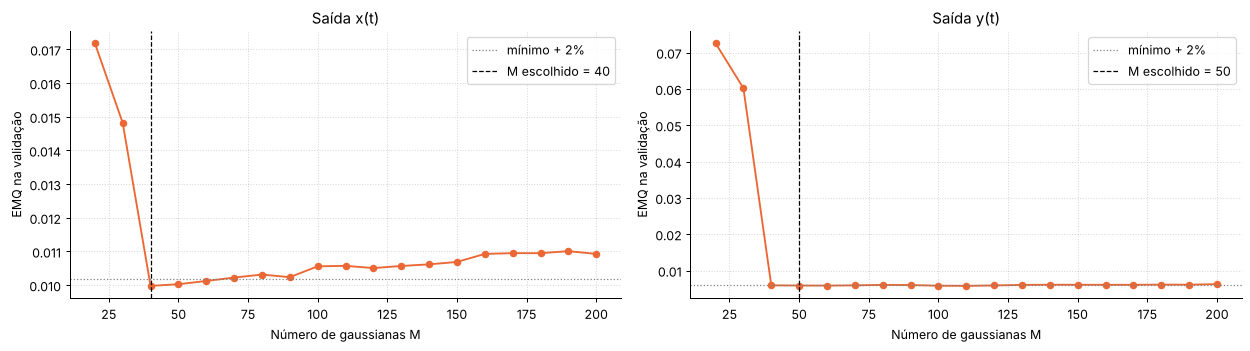

In [6]:
validacao = (np.arange(N) % 5 == 2)        # True para 1 de cada 5 amostras
treino = ~validacao
lista_M = np.arange(20, 201, 10)            # M = 20, 30, ..., 200

M_escolhido = {}
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for k, (nome, sinal) in enumerate([("x", x), ("y", y)]):
    erros_val = []
    for M in lista_M:
        w, c, s = ajustar_rbf(t[treino], sinal[treino], M)
        previsto_val = matriz_phi(t[validacao], c, s) @ w
        erros_val.append(emq(sinal[validacao], previsto_val))
    erros_val = np.array(erros_val)

    # Regra da parcimônia: o MENOR M cujo erro fica até 2% acima do mínimo encontrado
    limite = 1.02 * erros_val.min()
    M_escolhido[nome] = int(lista_M[np.where(erros_val <= limite)[0][0]])

    ax[k].plot(lista_M, erros_val, "o-", color=COR_MODELO, ms=5)
    ax[k].axhline(limite, color="0.5", ls=":", lw=1, label="mínimo + 2%")
    ax[k].axvline(M_escolhido[nome], color="k", ls="--", lw=1, label=f"M escolhido = {M_escolhido[nome]}")
    ax[k].set_title(f"Saída {nome}(t)")
    ax[k].set_xlabel("Número de gaussianas M"); ax[k].set_ylabel("EMQ na validação"); ax[k].legend()
    print(f"{nome}(t): menor EMQ de validação = {erros_val.min():.5f} (M = {lista_M[np.argmin(erros_val)]})"
          f"  ->  M escolhido = {M_escolhido[nome]} (EMQ = {erros_val[lista_M == M_escolhido[nome]][0]:.5f})")
plt.tight_layout()
plt.show()

A curva de validação cai muito de $M=20$ para $M \approx 40$ e depois fica quase plana ou **volta a subir**: a partir daí, gaussianas extras só servem para copiar o ruído. Resultado: $M = 40$ para $x(t)$ (centros a $\approx 0{,}77$ s um do outro) e $M = 50$ para $y(t)$ (centros a $\approx 0{,}61$ s), espaçamentos suficientes para acompanhar oscilações de período 2 s. Com $M = 20$ (centros a 1,58 s) a curva fica rígida demais para seguir essas oscilações, por isso o erro é tão alto.

### 3.5 Etapa 01 — Ajuste obtido
Agora ajustamos com **todos** os dados usando o $M$ escolhido.

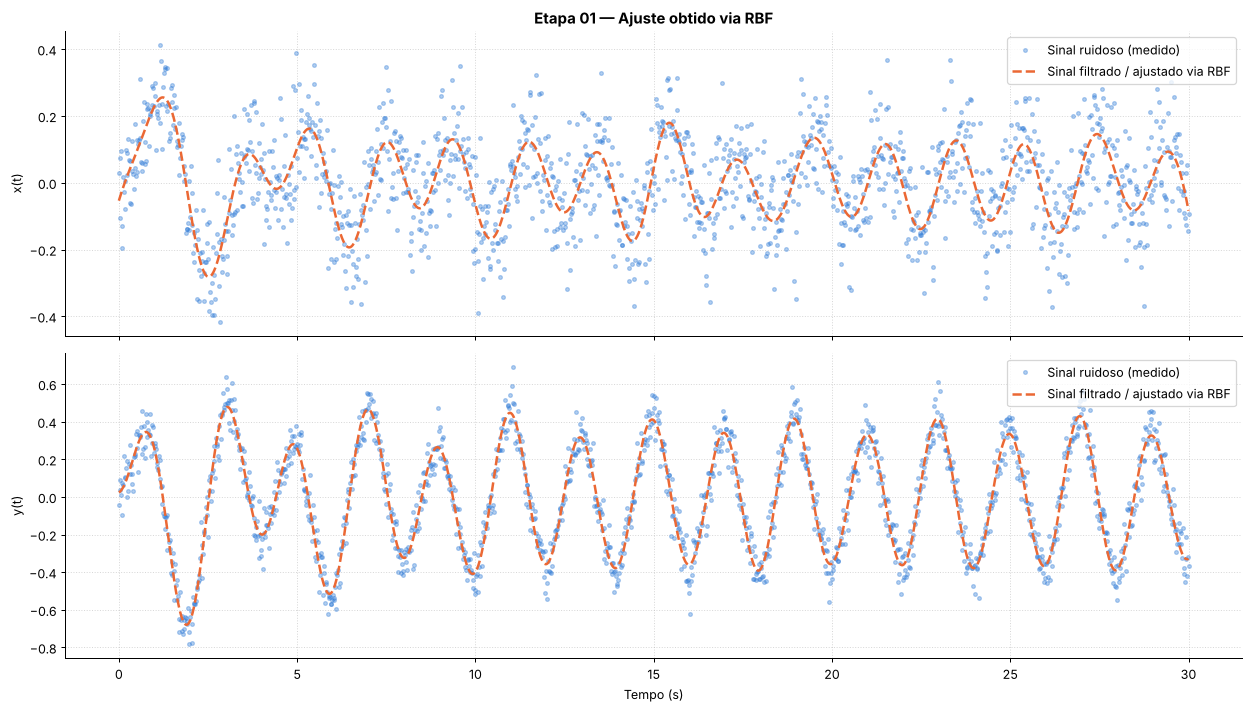

In [7]:
w_x, c_x, s_x = ajustar_rbf(t, x, M_escolhido["x"])
w_y, c_y, s_y = ajustar_rbf(t, y, M_escolhido["y"])

x_rbf = matriz_phi(t, c_x, s_x) @ w_x       # x(t) filtrado / ajustado via RBF
y_rbf = matriz_phi(t, c_y, s_y) @ w_y       # y(t) filtrado / ajustado via RBF

fig, ax = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
for a, medido, ajuste, nome in [(ax[0], x, x_rbf, "x"), (ax[1], y, y_rbf, "y")]:
    a.plot(t, medido, "o", ms=3, alpha=0.35, color=COR_MEDIDO, label="Sinal ruidoso (medido)")
    a.plot(t, ajuste, "--", lw=2, color=COR_MODELO, label="Sinal filtrado / ajustado via RBF")
    a.set_ylabel(f"{nome}(t)"); a.legend(loc="upper right")
ax[0].set_title("Etapa 01 — Ajuste obtido via RBF", fontweight="bold")
ax[1].set_xlabel("Tempo (s)")
plt.tight_layout()
plt.show()

**Para entender como a curva é construída**, o gráfico abaixo mostra um trecho de 0 a 4 s de $y(t)$: cada gaussiana multiplicada pelo seu peso ($w_j\,\phi_j$, linhas finas) e a soma de todas elas mais $w_0$ (curva grossa). A curva final é literalmente uma **soma de sinos**.

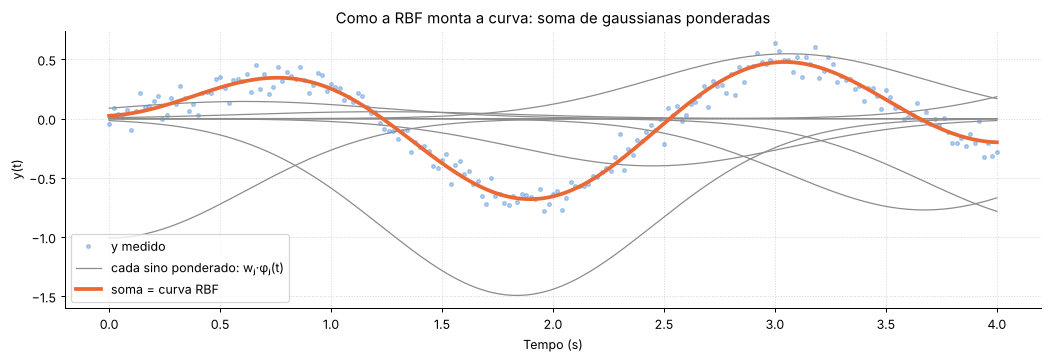

In [8]:
trecho = t <= 4
Phi_y = matriz_phi(t, c_y, s_y)
plt.figure(figsize=(14, 4))
plt.plot(t[trecho], y[trecho], "o", ms=3, alpha=0.35, color=COR_MEDIDO, label="y medido")
for j in range(M_escolhido["y"]):
    if c_y[j] <= 5:                                  # só os sinos próximos do trecho
        plt.plot(t[trecho], w_y[j + 1] * Phi_y[trecho, j + 1], color="0.55", lw=1)
plt.plot([], [], color="0.55", lw=1, label="cada sino ponderado: wⱼ·φⱼ(t)")
plt.plot(t[trecho], y_rbf[trecho], color=COR_MODELO, lw=3, label="soma = curva RBF")
plt.title("Como a RBF monta a curva: soma de gaussianas ponderadas")
plt.xlabel("Tempo (s)"); plt.ylabel("y(t)"); plt.legend(loc="lower left")
plt.show()

### 3.6 Parâmetros livres obtidos (modelo RBF)

In [9]:
for nome, w, c, s in [("x", w_x, c_x, s_x), ("y", w_y, c_y, s_y)]:
    print(f"Modelo RBF para {nome}(t):")
    print(f"  M = {len(c)} gaussianas | centros de {c[0]:.2f} a {c[-1]:.2f} s | σ = {s:.4f} s")
    print(f"  total de pesos ajustados = {len(w)} (w0 + {len(c)})")
    print(f"  w0 = {w[0]:.4f} | primeiros pesos w1..w5 = {np.round(w[1:6], 4)}")
    print()

Modelo RBF para x(t):
  M = 40 gaussianas | centros de 0.00 a 30.00 s | σ = 0.7692 s
  total de pesos ajustados = 41 (w0 + 40)
  w0 = -0.9265 | primeiros pesos w1..w5 = [ 0.7695 -0.1234  1.3648 -0.5982  0.5997]

Modelo RBF para y(t):
  M = 50 gaussianas | centros de 0.00 a 30.00 s | σ = 0.6122 s
  total de pesos ajustados = 51 (w0 + 50)
  w0 = 0.9532 | primeiros pesos w1..w5 = [-1.0079  0.1452  0.0586 -1.4922 -0.3987]



### 3.7 Etapa 02 — Erro Médio Quadrático (EMQ) do ajuste RBF

EMQ x(t) = 0.00975   ->  erro típico √EMQ = 0.0987
EMQ y(t) = 0.00535   ->  erro típico √EMQ = 0.0731


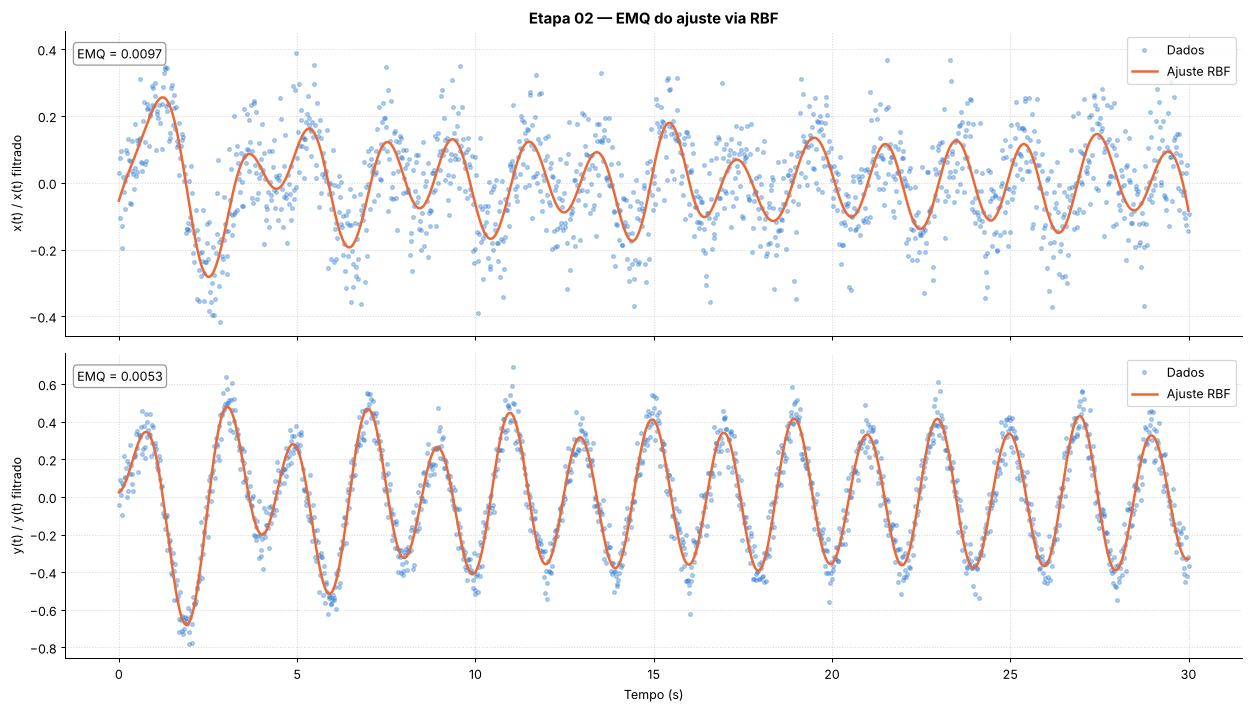

In [10]:
EMQ_x_rbf = emq(x, x_rbf)
EMQ_y_rbf = emq(y, y_rbf)

fig, ax = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
for a, medido, ajuste, nome, e in [(ax[0], x, x_rbf, "x", EMQ_x_rbf), (ax[1], y, y_rbf, "y", EMQ_y_rbf)]:
    a.plot(t, medido, "o", ms=3, alpha=0.35, color=COR_MEDIDO, label="Dados")
    a.plot(t, ajuste, lw=2, color=COR_MODELO, label="Ajuste RBF")
    a.text(0.01, 0.95, f"EMQ = {e:.4f}", transform=a.transAxes, va="top",
           bbox=dict(boxstyle="round", fc="white", ec="0.6"))
    a.set_ylabel(f"{nome}(t) / {nome}(t) filtrado"); a.legend(loc="upper right")
ax[0].set_title("Etapa 02 — EMQ do ajuste via RBF", fontweight="bold")
ax[1].set_xlabel("Tempo (s)")
plt.tight_layout()
plt.show()

print(f"EMQ x(t) = {EMQ_x_rbf:.5f}   ->  erro típico √EMQ = {np.sqrt(EMQ_x_rbf):.4f}")
print(f"EMQ y(t) = {EMQ_y_rbf:.5f}   ->  erro típico √EMQ = {np.sqrt(EMQ_y_rbf):.4f}")

**Como interpretar:** o EMQ aqui é praticamente o **tamanho do ruído** (variância do ruído). Isso é o desejado: a curva RBF não tenta acompanhar o ruído, então o que sobra (o erro) é justamente o ruído. Um EMQ muito menor indicaria sobreajuste (a curva estaria copiando o ruído).

### 3.8 Etapa 03 — Regressão linear entre dados reais e ajustados + Correlação de Pearson
Cada ponto do gráfico é um instante de tempo: no eixo horizontal o valor **ajustado** pela RBF, no vertical o valor **medido**. Se o ajuste for bom, a nuvem segue uma reta. As faixas mostram $\pm\sqrt{\text{EMQ}}$ em torno da reta de regressão.

x(t): reta real = 0.0000 + 1.0000·ajustado | Pearson r = 0.7252 | r² = 0.5259
y(t): reta real = -0.0000 + 1.0000·ajustado | Pearson r = 0.9675 | r² = 0.9361


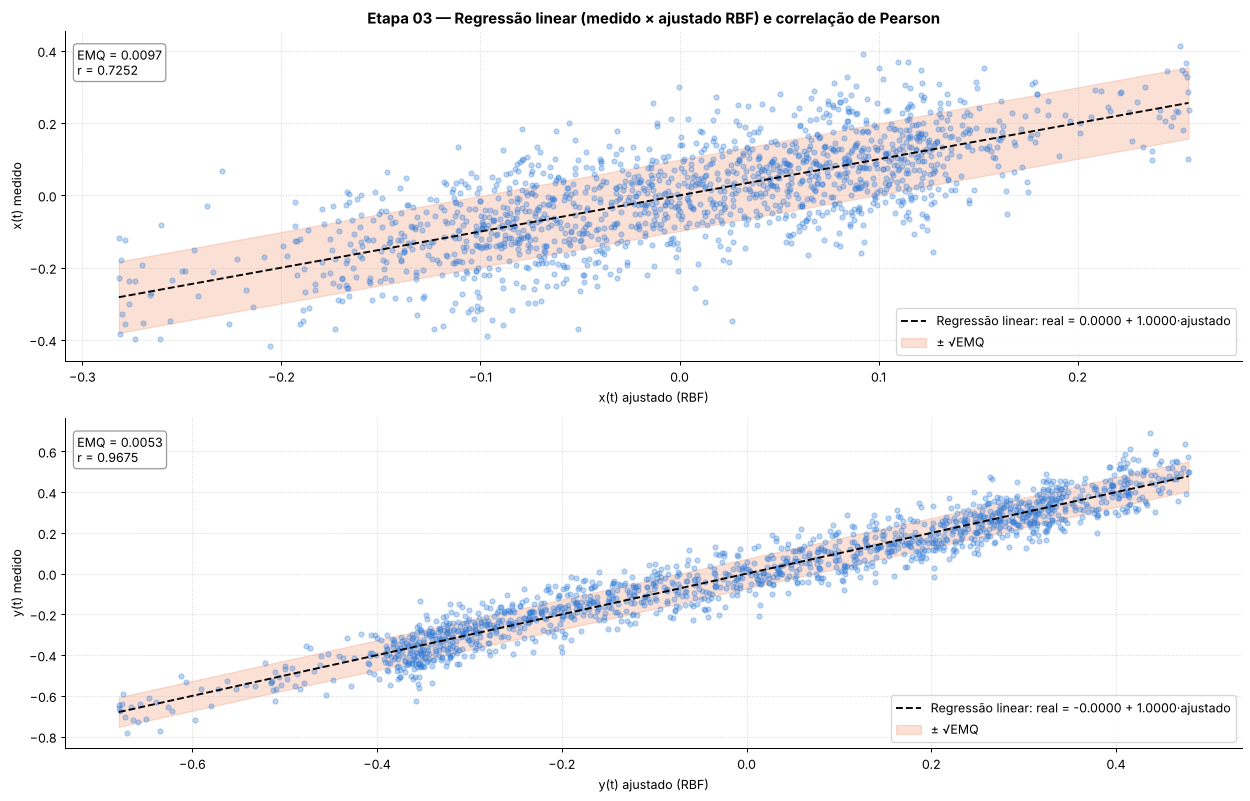

In [11]:
def grafico_regressao(ax, ajustado, real, nome, cor_faixa, rotulo_modelo):
    alfa, beta = regressao_linear(ajustado, real)
    r = pearson(real, ajustado)
    e = emq(real, ajustado)
    xs = np.linspace(ajustado.min(), ajustado.max(), 100)
    reta = alfa + beta * xs
    ax.plot(ajustado, real, "o", ms=4, alpha=0.3, color=COR_MEDIDO)
    ax.plot(xs, reta, "k--", lw=1.5, label=f"Regressão linear: real = {alfa:.4f} + {beta:.4f}·ajustado")
    ax.fill_between(xs, reta - np.sqrt(e), reta + np.sqrt(e), color=cor_faixa, alpha=0.2, label="± √EMQ")
    ax.text(0.01, 0.95, f"EMQ = {e:.4f}\nr = {r:.4f}", transform=ax.transAxes, va="top",
            bbox=dict(boxstyle="round", fc="white", ec="0.6"))
    ax.set_xlabel(f"{nome}(t) ajustado ({rotulo_modelo})"); ax.set_ylabel(f"{nome}(t) medido")
    ax.legend(loc="lower right")
    return alfa, beta, r

fig, ax = plt.subplots(2, 1, figsize=(14, 9))
alfa_x_rbf, beta_x_rbf, r_x_rbf = grafico_regressao(ax[0], x_rbf, x, "x", COR_MODELO, "RBF")
alfa_y_rbf, beta_y_rbf, r_y_rbf = grafico_regressao(ax[1], y_rbf, y, "y", COR_MODELO, "RBF")
ax[0].set_title("Etapa 03 — Regressão linear (medido × ajustado RBF) e correlação de Pearson", fontweight="bold")
plt.tight_layout()
plt.show()

print(f"x(t): reta real = {alfa_x_rbf:.4f} + {beta_x_rbf:.4f}·ajustado | Pearson r = {r_x_rbf:.4f} | r² = {r_x_rbf**2:.4f}")
print(f"y(t): reta real = {alfa_y_rbf:.4f} + {beta_y_rbf:.4f}·ajustado | Pearson r = {r_y_rbf:.4f} | r² = {r_y_rbf**2:.4f}")

**Leitura dos resultados:**
* A inclinação deu **exatamente 1** e o intercepto **exatamente 0**. Isso não é coincidência: é uma propriedade do MMQ com termo constante ($w_0$). Quando os pesos minimizam o EMQ, o erro fica "perpendicular" (ortogonal) tanto à coluna de 1s quanto à própria curva ajustada — então a melhor reta entre medido e ajustado é $y = 0 + 1\cdot\hat y$. Em palavras: **o ajuste não tem viés** (não superestima nem subestima sistematicamente).
* O $r$ de $y(t)$ é bem maior que o de $x(t)$. Não é porque a RBF "errou mais" em $x$: os dois EMQ estão no nível do ruído. A diferença é que em $x$ o **ruído é quase do tamanho do sinal** (relação sinal/ruído baixa), então mesmo a curva verdadeira teria correlação moderada com os pontos medidos. Em $y$, o sinal é grande comparado ao ruído.

---
## 4. Parte B — Repetição do processo com o Método dos Mínimos Quadrados (MMQ)

### 4.1 O modelo dinâmico
Agora usamos diretamente a estrutura pedida no enunciado, $y[n] = f(y[n-2], y[n-1], u[n], u[n-1])$, com $f$ **linear** (uma combinação linear dos regressores):
$$\boxed{y[n] = a_1\,y[n-1] + a_2\,y[n-2] + b_0\,u[n] + b_1\,u[n-1]}$$
Essa é uma **equação de diferenças** (modelo ARX de 2ª ordem): é a versão discreta de uma equação diferencial de 2ª ordem (como massa-mola-amortecedor ou circuito RLC). Os **parâmetros livres** são $a_1, a_2, b_0, b_1$:
* $a_1, a_2$ descrevem a "memória"/inércia do sistema (como ele responde ao seu próprio passado);
* $b_0, b_1$ descrevem como a entrada $u$ empurra a saída.

### 4.2 Forma matricial e solução por MMQ
Para cada instante $n = 2, 3, \dots, N-1$ escrevemos uma linha:
$$\underbrace{\begin{bmatrix} y[1] & y[0] & u[2] & u[1]\\ y[2] & y[1] & u[3] & u[2] \\ \vdots & \vdots & \vdots & \vdots \\ y[N-2] & y[N-3] & u[N-1] & u[N-2]\end{bmatrix}}_{A\;((N-2)\times 4)} \underbrace{\begin{bmatrix} a_1\\a_2\\b_0\\b_1\end{bmatrix}}_{\theta} \approx \underbrace{\begin{bmatrix} y[2]\\ y[3]\\ \vdots\\ y[N-1]\end{bmatrix}}_{\mathbf b}$$
São 1499 equações e só 4 incógnitas (sistema sobredeterminado). O MMQ escolhe o $\theta$ que minimiza a soma dos erros ao quadrado, o que leva de novo à **equação normal**:
$$\boxed{A^TA\,\theta = A^T\mathbf b}$$
(É exatamente a mesma matemática da RBF; só mudam as colunas da matriz.)

In [12]:
def montar_regressores(s, u):
    # Cada linha: [s[n-1], s[n-2], u[n], u[n-1]] para n = 2, ..., N-1
    A = np.column_stack((s[1:-1],      # s[n-1]
                         s[:-2],       # s[n-2]
                         u[2:],        # u[n]
                         u[1:-1]))     # u[n-1]
    b = s[2:]                          # s[n] (o que queremos prever)
    return A, b

def ajustar_mmq(s, u):
    A, b = montar_regressores(s, u)
    theta = np.linalg.solve(A.T @ A, A.T @ b)               # (Aᵀ A) θ = Aᵀ b
    return theta

theta_x = ajustar_mmq(x, u)
theta_y = ajustar_mmq(y, u)

print("Parâmetros livres do modelo y[n] = a1·y[n-1] + a2·y[n-2] + b0·u[n] + b1·u[n-1]\n")
print(f"{'saída':<8}{'a1':>10}{'a2':>10}{'b0':>10}{'b1':>10}")
for nome, th in [("x", theta_x), ("y", theta_y)]:
    print(f"{nome:<8}{th[0]:>10.4f}{th[1]:>10.4f}{th[2]:>10.4f}{th[3]:>10.4f}")

Parâmetros livres do modelo y[n] = a1·y[n-1] + a2·y[n-2] + b0·u[n] + b1·u[n-1]

saída           a1        a2        b0        b1
x           0.2984    0.2118   -0.0216   -0.0150
y           0.4876    0.4649   -0.0159    0.0426


### 4.3 Etapa 04 — Ajuste obtido via MMQ (predição um passo à frente)
Com $\theta$ calculado, a previsão para cada instante usa os **valores medidos** anteriores:
$$\hat y[n] = a_1\,y[n-1] + a_2\,y[n-2] + b_0\,u[n] + b_1\,u[n-1]$$
Isso se chama **predição um passo à frente**: a cada amostra o modelo "olha" o que realmente foi medido antes e prevê só o próximo valor.

EMQ x(t) via MMQ = 0.01226
EMQ y(t) via MMQ = 0.00753


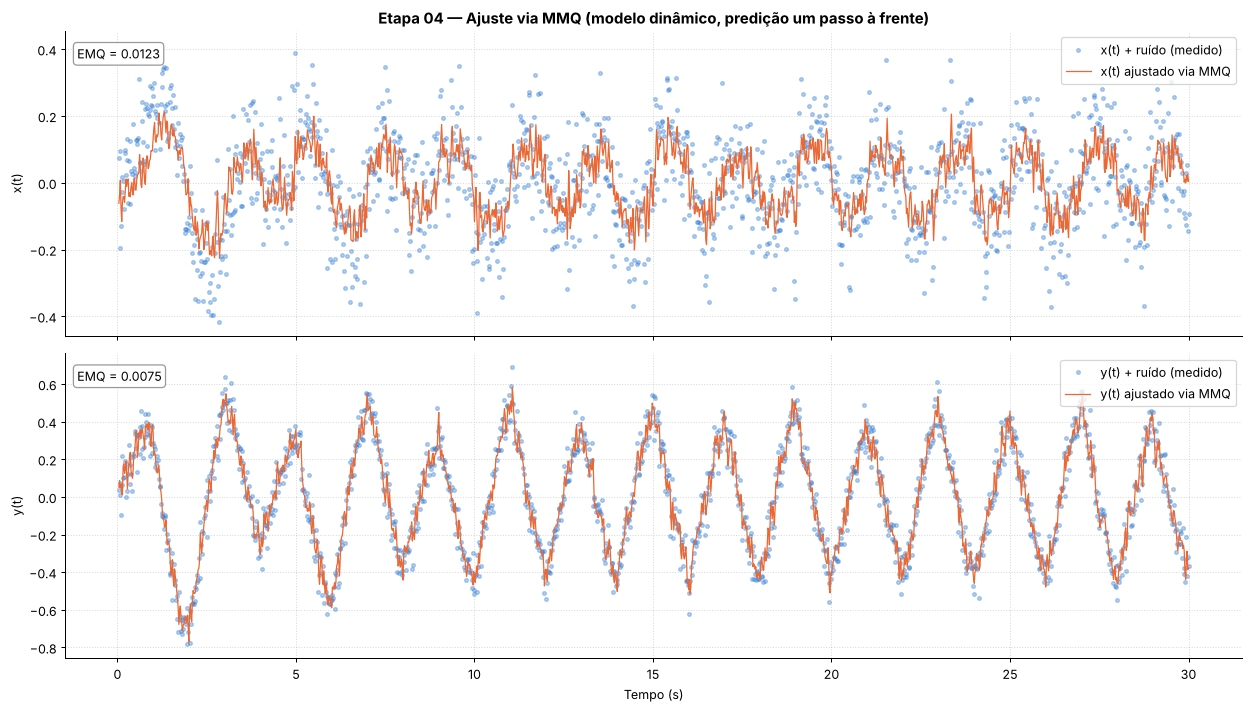

In [13]:
A_x, alvo_x = montar_regressores(x, u)
A_y, alvo_y = montar_regressores(y, u)
x_mmq = A_x @ theta_x        # previsões para n = 2, ..., N-1
y_mmq = A_y @ theta_y
t_mmq = t[2:]                # instantes correspondentes

EMQ_x_mmq = emq(alvo_x, x_mmq)
EMQ_y_mmq = emq(alvo_y, y_mmq)

fig, ax = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
for a, medido, ajuste, nome, e in [(ax[0], alvo_x, x_mmq, "x", EMQ_x_mmq), (ax[1], alvo_y, y_mmq, "y", EMQ_y_mmq)]:
    a.plot(t_mmq, medido, "o", ms=3, alpha=0.35, color=COR_MEDIDO, label=f"{nome}(t) + ruído (medido)")
    a.plot(t_mmq, ajuste, lw=1, color=COR_MODELO, label=f"{nome}(t) ajustado via MMQ")
    a.text(0.01, 0.95, f"EMQ = {e:.4f}", transform=a.transAxes, va="top",
           bbox=dict(boxstyle="round", fc="white", ec="0.6"))
    a.set_ylabel(f"{nome}(t)"); a.legend(loc="upper right")
ax[0].set_title("Etapa 04 — Ajuste via MMQ (modelo dinâmico, predição um passo à frente)", fontweight="bold")
ax[1].set_xlabel("Tempo (s)")
plt.tight_layout()
plt.show()

print(f"EMQ x(t) via MMQ = {EMQ_x_mmq:.5f}")
print(f"EMQ y(t) via MMQ = {EMQ_y_mmq:.5f}")

Note que a curva do MMQ é **serrilhada**: como ela usa os valores medidos (com ruído) de $y[n-1]$ e $y[n-2]$, parte do ruído "entra" na previsão. A RBF, ao contrário, produz uma curva suave.

### 4.4 Regressão linear e correlação de Pearson do ajuste MMQ

x(t): reta real = 0.0022 + 0.9995·ajustado | Pearson r = 0.6361 | r² = 0.4046
y(t): reta real = -0.0007 + 1.0000·ajustado | Pearson r = 0.9541 | r² = 0.9102


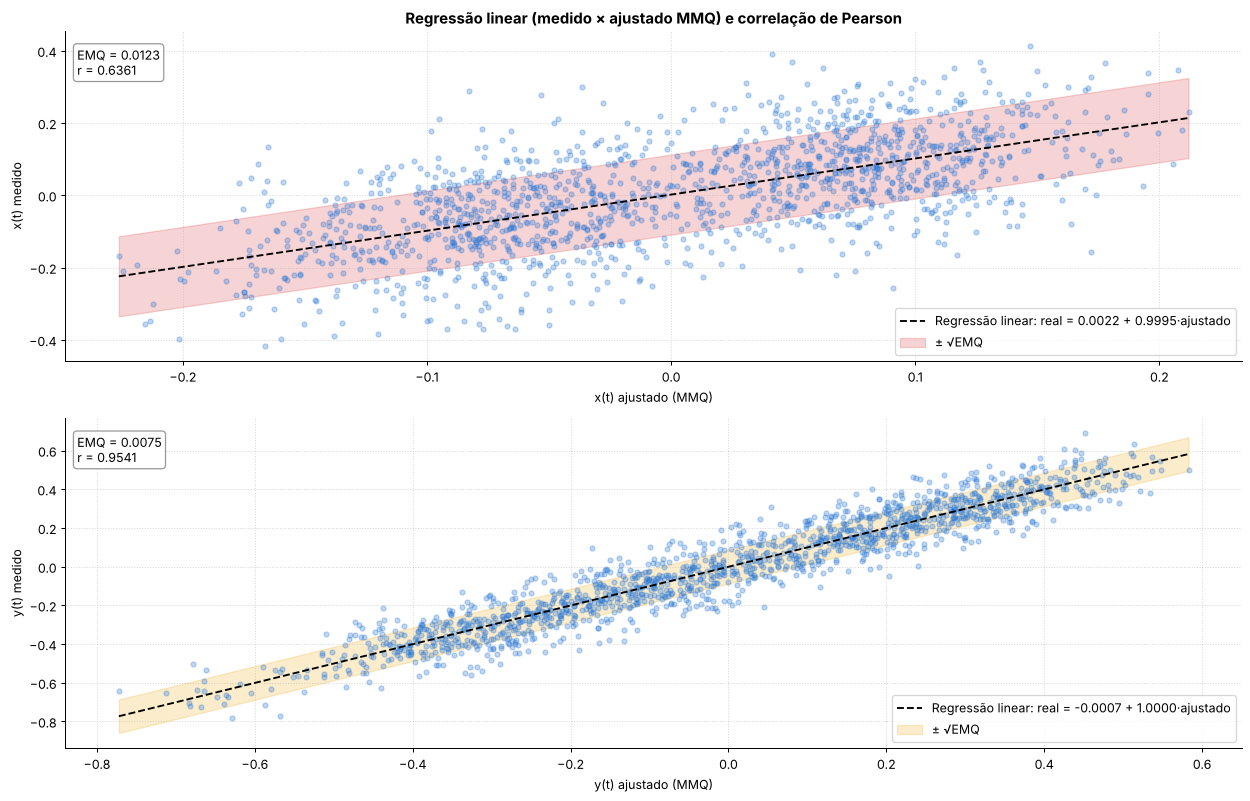

In [14]:
fig, ax = plt.subplots(2, 1, figsize=(14, 9))
alfa_x_mmq, beta_x_mmq, r_x_mmq = grafico_regressao(ax[0], x_mmq, alvo_x, "x", "tab:red", "MMQ")
alfa_y_mmq, beta_y_mmq, r_y_mmq = grafico_regressao(ax[1], y_mmq, alvo_y, "y", "#eda100", "MMQ")
ax[0].set_title("Regressão linear (medido × ajustado MMQ) e correlação de Pearson", fontweight="bold")
plt.tight_layout()
plt.show()

print(f"x(t): reta real = {alfa_x_mmq:.4f} + {beta_x_mmq:.4f}·ajustado | Pearson r = {r_x_mmq:.4f} | r² = {r_x_mmq**2:.4f}")
print(f"y(t): reta real = {alfa_y_mmq:.4f} + {beta_y_mmq:.4f}·ajustado | Pearson r = {r_y_mmq:.4f} | r² = {r_y_mmq**2:.4f}")

### 4.5 Complemento — o modelo MMQ consegue *simular* o sistema sozinho?
A predição um passo à frente "trapaceia" um pouco: ela sempre recebe o valor medido anterior. O teste mais exigente de um modelo dinâmico é a **simulação livre**: damos ao modelo **apenas a entrada $u$** e as duas primeiras amostras, e ele usa as **próprias previsões** como passado:
$$\hat y[n] = a_1\,\hat y[n-1] + a_2\,\hat y[n-2] + b_0\,u[n] + b_1\,u[n-1]$$
Se o modelo tivesse capturado a dinâmica verdadeira, essa simulação reproduziria o sinal.

x(t) simulação livre: EMQ = 0.01497 | Pearson r = 0.5238
y(t) simulação livre: EMQ = 0.01970 | Pearson r = 0.8777


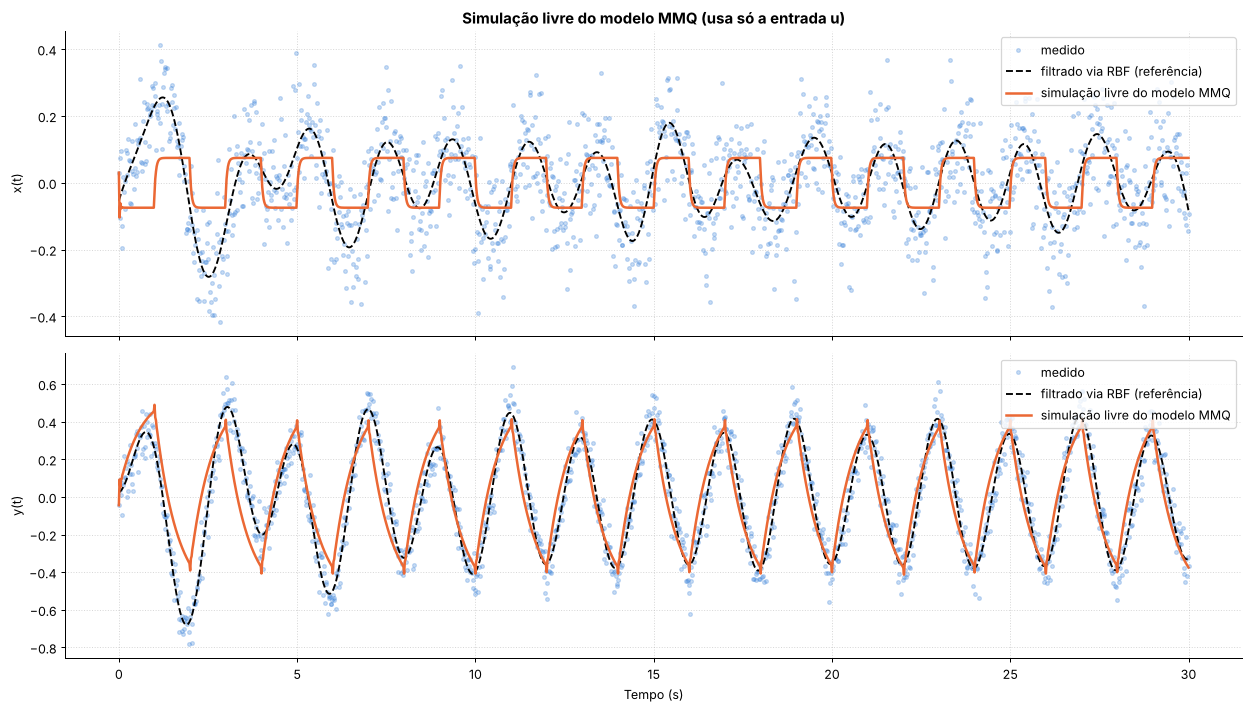

In [15]:
def simular_livre(theta, u, s_inicial):
    a1, a2, b0, b1 = theta
    s_sim = np.zeros(len(u))
    s_sim[0], s_sim[1] = s_inicial[0], s_inicial[1]        # condições iniciais = 2 primeiras medidas
    for n in range(2, len(u)):
        s_sim[n] = a1 * s_sim[n - 1] + a2 * s_sim[n - 2] + b0 * u[n] + b1 * u[n - 1]
    return s_sim

x_sim = simular_livre(theta_x, u, x)
y_sim = simular_livre(theta_y, u, y)

fig, ax = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
for a, medido, rbf, sim, nome in [(ax[0], x, x_rbf, x_sim, "x"), (ax[1], y, y_rbf, y_sim, "y")]:
    a.plot(t, medido, "o", ms=3, alpha=0.25, color=COR_MEDIDO, label="medido")
    a.plot(t, rbf, color="k", lw=1.5, ls="--", label="filtrado via RBF (referência)")
    a.plot(t, sim, color=COR_MODELO, lw=2, label="simulação livre do modelo MMQ")
    a.set_ylabel(f"{nome}(t)"); a.legend(loc="upper right")
ax[0].set_title("Simulação livre do modelo MMQ (usa só a entrada u)", fontweight="bold")
ax[1].set_xlabel("Tempo (s)")
plt.tight_layout()
plt.show()

for nome, medido, sim in [("x", x, x_sim), ("y", y, y_sim)]:
    print(f"{nome}(t) simulação livre: EMQ = {emq(medido[2:], sim[2:]):.5f} | Pearson r = {pearson(medido[2:], sim[2:]):.4f}")

**Leitura:** na simulação livre o desempenho cai — bastante em $x(t)$ e um pouco em $y(t)$. O motivo é um fenômeno conhecido do MMQ: quando os **regressores** ($y[n-1]$, $y[n-2]$) também têm ruído, os parâmetros estimados ficam **enviesados** (o MMQ "desconfia" do passado ruidoso e subestima a memória do sistema). Veja os valores de $a_1, a_2$: para um sistema que oscila suavemente amostrado a cada 0,02 s, esperaríamos $a_1 \approx 2$ e $a_2 \approx -1$; o ruído os puxou para valores bem menores.

---
## 5. Comparação final

In [16]:
print(f"{'Modelo':<34}{'Saída':<7}{'EMQ':>10}{'√EMQ':>9}{'Pearson r':>11}{'r²':>8}")
print("-" * 79)
linhas_tabela = [
    ("RBF (filtragem no tempo)",           "x", emq(x, x_rbf),          pearson(x, x_rbf)),
    ("RBF (filtragem no tempo)",           "y", emq(y, y_rbf),          pearson(y, y_rbf)),
    ("MMQ - predição um passo à frente",   "x", EMQ_x_mmq,              r_x_mmq),
    ("MMQ - predição um passo à frente",   "y", EMQ_y_mmq,              r_y_mmq),
    ("MMQ - simulação livre",              "x", emq(x[2:], x_sim[2:]),  pearson(x[2:], x_sim[2:])),
    ("MMQ - simulação livre",              "y", emq(y[2:], y_sim[2:]),  pearson(y[2:], y_sim[2:])),
]
for modelo, saida, e, r in linhas_tabela:
    print(f"{modelo:<34}{saida:<7}{e:>10.5f}{np.sqrt(e):>9.4f}{r:>11.4f}{r**2:>8.4f}")

print(f"\nNúmero de parâmetros: RBF x = {len(w_x)}, RBF y = {len(w_y)}, MMQ = 4 por saída")

Modelo                            Saída         EMQ     √EMQ  Pearson r      r²
-------------------------------------------------------------------------------
RBF (filtragem no tempo)          x         0.00975   0.0987     0.7252  0.5259
RBF (filtragem no tempo)          y         0.00535   0.0731     0.9675  0.9361
MMQ - predição um passo à frente  x         0.01226   0.1107     0.6361  0.4046
MMQ - predição um passo à frente  y         0.00753   0.0868     0.9541  0.9102
MMQ - simulação livre             x         0.01497   0.1224     0.5238  0.2744
MMQ - simulação livre             y         0.01970   0.1404     0.8777  0.7703

Número de parâmetros: RBF x = 41, RBF y = 51, MMQ = 4 por saída


---
## 6. Conclusões

**1. A RBF obteve o melhor ajuste nas duas saídas.** Ela teve o menor EMQ ($x$: 0,0097; $y$: 0,0053) e a maior correlação ($x$: $r = 0{,}725$; $y$: $r = 0{,}968$). O EMQ ficou no nível da **variância do ruído**, e a curva segue a oscilação sem acompanhar a dispersão dos pontos: é exatamente o comportamento de um bom **filtro**. A regressão linear medido × ajustado deu inclinação 1 e intercepto 0, ou seja, o ajuste não tem viés.

**2. A escolha do número de gaussianas foi feita por validação.** Poucas gaussianas ($M = 20$) não acompanham a oscilação (EMQ de validação até 12 vezes maior em $y$). Gaussianas demais começam a copiar o ruído (o erro de validação volta a subir em $x$). Pela regra da parcimônia ficamos com $M = 40$ para $x$ e $M = 50$ para $y$.

**3. O MMQ (modelo dinâmico de 2ª ordem) chegou perto da RBF com apenas 4 parâmetros.** Na predição um passo à frente: $x$: EMQ = 0,0123, $r = 0{,}636$; $y$: EMQ = 0,0075, $r = 0{,}954$. Os parâmetros livres identificados foram:

| Saída | $a_1$ | $a_2$ | $b_0$ | $b_1$ |
|---|---|---|---|---|
| $x$ | 0,2984 | 0,2118 | −0,0216 | −0,0150 |
| $y$ | 0,4876 | 0,4649 | −0,0159 | 0,0426 |

**4. Os dois modelos têm papéis diferentes.** A RBF usa 41 a 51 parâmetros para **descrever** estes 30 s de sinal (é uma função do tempo e não sabe o que aconteceria com outra entrada). O modelo MMQ usa 4 parâmetros e **relaciona a entrada com a saída**, então pode ser usado para prever a resposta a uma entrada nova. Mais parâmetros dão mais flexibilidade, mas não explicam o sistema.

**5. A saída $y$ é sempre melhor modelada que $x$, com qualquer método.** O motivo é a **relação sinal/ruído**: em $x$, o erro típico ($\sqrt{\text{EMQ}} \approx 0{,}10$) é do tamanho da amplitude do sinal ($\approx 0{,}1$ a $0{,}25$), enquanto em $y$ a amplitude ($\approx 0{,}4$ a $0{,}7$) é bem maior que o ruído ($\approx 0{,}07$). Com tanto ruído, mesmo um modelo perfeito teria correlação moderada com os pontos medidos de $x$.

**6. Limitação do MMQ com ruído nos regressores.** Na simulação livre (o modelo só recebe a entrada $u$), $y$ ainda é razoável ($r = 0{,}878$), mas $x$ cai para $r = 0{,}524$ e reproduz apenas uma onda quadrada. Como $y[n-1]$ e $y[n-2]$ também são medidas ruidosas, o MMQ estima $a_1, a_2$ **enviesados** (menores do que deveriam) e o modelo perde a "memória" que gera a oscilação. Caminhos para melhorar: identificar o modelo a partir do sinal já filtrado, usar ordens maiores, ou métodos próprios para ruído nos regressores (ex.: variáveis instrumentais).

**7. EMQ e Pearson se complementam.** O EMQ mede o **tamanho** do erro (na unidade do sinal ao quadrado). O $r$ mede se a **forma** do sinal foi capturada, independentemente da escala. Usar os dois evita conclusões erradas: um modelo pode ter $r$ alto e ainda assim estar deslocado ou com amplitude errada, o que só o EMQ (e a regressão com $\beta \approx 1$, $\alpha \approx 0$) revelaria.